# Identificação do projeto

**Título do projeto:** Adoção de gatos no Austin Animal Center: características associadas à adoção

**Integrantes do grupo:** Ayla Micheluzzi e Gabriel Baczinski

**Turma:** Bacharelado em Sistemas de Informação • 6º período, turma U (noite) • 2026/2 • Profa. Marina de Lara

**Etapa:** RA3 – análise estatística, visualização e Machine Learning. O RA1 e o RA2 estão em `projeto_adocao_gatinhos.ipynb`; este notebook parte do dataset que o RA1 gerou (`data/processed/gatos_ra1.csv`).

**Como executar:** Python 3.11+; `pip install -r requirements.txt` e *Run All* (menos de 1 minuto, não precisa de Spark nem de Java). Se o CSV não existir, rode antes o notebook do RA1. O dashboard fica em `dashboard/app.py` (`streamlit run dashboard/app.py`).

## 1. Objetivo e dados utilizados

O RA1 definiu o problema: **quais características do gato na chegada estão associadas à chance de adoção e ao tempo até a adoção?** e preparou o dataset sem responder às perguntas P1 a P7. Aqui elas são respondidas, seguindo as regras definidas no RA1:

- **chance de adoção** = % das passagens com saída que terminam em adoção;
- **tempo até a adoção** = `dias_no_abrigo` das adoções, com as adoções `Foster` separadas (o tempo delas inclui lar temporário);
- a medida principal é a **mediana**, porque o tempo é muito assimétrico;
- as comparações são feitas **dentro de cada faixa etária**, porque a idade interfere em quase todas as outras características.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

gatos = pd.read_csv("../data/processed/gatos_ra1.csv", parse_dates=["data_entrada", "data_saida"])

# os três recortes usados no RA3
com_saida = gatos[gatos["desfecho"] != "sem_saida"].copy()            # base da chance de adoção
com_saida["adotado"] = com_saida["desfecho"] == "adocao"
adocoes = com_saida[com_saida["adotado"]].copy()
adocoes["foster"] = adocoes["subtipo_desfecho"] == "Foster"
adocoes_diretas = adocoes[~adocoes["foster"]]                          # base do tempo até a adoção

print("Passagens:", len(gatos), "| com saída:", len(com_saida), "| adoções:", len(adocoes),
      "| adoções sem Foster:", len(adocoes_diretas))

Passagens: 69309 | com saída: 68899 | adoções: 35433 | adoções sem Foster: 25409


## 2. Análise estatística descritiva

Duas variáveis respondem ao problema: o **desfecho** (categórica, de onde sai a chance de adoção) e o **tempo até a adoção** (numérica). A idade na entrada também é descrita, porque é a característica que mais muda o resto.

### 2.1 Desfecho: frequência e chance de adoção

In [2]:
freq = com_saida["desfecho"].value_counts()
pd.DataFrame({"passagens": freq, "%": (100 * freq / freq.sum()).round(1)})

,passagens,%
desfecho,,
adocao,35433,51.4
transferencia,26577,38.6
devolvido_ao_dono,2857,4.1
eutanasia,2555,3.7
morte,998,1.4
rto-adopt,249,0.4
disposal,164,0.2
desaparecido,51,0.1
desconhecido,9,0.0


**Interpretação:** pouco mais da metade das passagens termina em **adoção (51,4%)**, e o segundo destino é a **transferência (38,6%)** para organizações parceiras. Juntos, os dois somam 90% das saídas. Como a variável é categórica, a medida de tendência central possível é a **moda** (adoção). Essa proporção quase equilibrada entre adotados e não adotados importa para o ML (seção 5): um modelo que chuta sempre "adotado" acerta só ~51%.

### 2.2 Tempo até a adoção e idade: tendência central e dispersão

In [3]:
def resumo(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    return pd.Series({
        "n": len(serie),
        "média": serie.mean(),
        "mediana": serie.median(),
        "desvio-padrão": serie.std(),
        "Q1": q1,
        "Q3": q3,
        "IQR (Q3 - Q1)": q3 - q1,
        "mínimo": serie.min(),
        "máximo": serie.max(),
        "amplitude": serie.max() - serie.min(),
        "assimetria": serie.skew(),
    })


pd.DataFrame({
    "dias até adoção (sem Foster)": resumo(adocoes_diretas["dias_no_abrigo"]),
    "dias até adoção (Foster)": resumo(adocoes.loc[adocoes["foster"], "dias_no_abrigo"]),
    "idade na entrada (meses)": resumo(gatos["idade_entrada_meses"].dropna()),
}).round(1)

,dias até adoção (sem Foster),dias até adoção (Foster),idade na entrada (meses)
n,25409.0,10024.0,69308.0
média,24.7,73.2,15.4
mediana,13.0,55.0,2.0
desvio-padrão,29.8,76.4,30.3
Q1,6.0,38.0,0.9
Q3,35.0,81.0,12.0
IQR (Q3 - Q1),29.0,43.0,11.1
mínimo,0.0,0.0,0.0
máximo,579.0,1745.0,264.0
amplitude,579.0,1745.0,264.0


**Interpretação:**
- Nas adoções diretas, a **média (24,7 dias) é quase o dobro da mediana (13 dias)**. Isso acontece porque poucos gatos que esperam meses puxam a média pra cima (assimetria 3,7). Por isso usamos a **mediana**: metade dos gatos é adotada em até 13 dias.
- O **desvio-padrão (29,8)** é maior que a própria média e a **amplitude (0 a 579 dias)** é enorme: o tempo varia muito de um gato pra outro. O **IQR** mostra que a metade central dos gatos espera entre 6 e 35 dias.
- As adoções **Foster** têm mediana de 55 dias, 4 vezes a das diretas. Confirma a decisão do RA1 de analisá-las separadas: misturadas, elas distorceriam o tempo de espera.
- A **idade** também é muito assimétrica: a mediana é de 2 meses (dois terços dos gatos chegam filhotes), mas a média passa de 15 meses por causa dos adultos e idosos.

### 2.3 Distribuição do tempo até a adoção

                 adoções     %  % acumulado
dias_no_abrigo                             
até 1 semana        8832  34.8         34.8
8 a 30 dias         9312  36.6         71.4
31 a 90 dias        6405  25.2         96.6
91 dias a 1 ano      849   3.3        100.0
mais de 1 ano         11   0.0        100.0


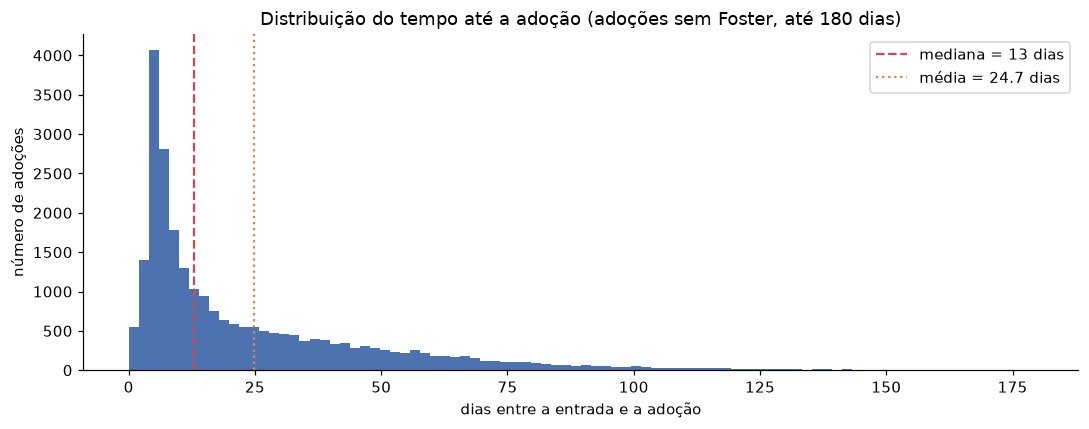

Fora do gráfico (mais de 180 dias): 80 adoções (0.3%)


In [4]:
dias = adocoes_diretas["dias_no_abrigo"]

# frequência por faixas de tempo
faixas = pd.cut(dias, bins=[-1, 7, 30, 90, 365, dias.max()],
                labels=["até 1 semana", "8 a 30 dias", "31 a 90 dias", "91 dias a 1 ano", "mais de 1 ano"])
contagem = faixas.value_counts().sort_index()
print(pd.DataFrame({"adoções": contagem, "%": (100 * contagem / contagem.sum()).round(1),
                    "% acumulado": (100 * contagem.cumsum() / contagem.sum()).round(1)}))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(dias[dias <= 180], bins=90, color="#4C72B0")
ax.axvline(dias.median(), color="#C44E52", linestyle="--", label=f"mediana = {dias.median():.0f} dias")
ax.axvline(dias.mean(), color="#DD8452", linestyle=":", label=f"média = {dias.mean():.1f} dias")
ax.set_title("Distribuição do tempo até a adoção (adoções sem Foster, até 180 dias)")
ax.set_xlabel("dias entre a entrada e a adoção")
ax.set_ylabel("número de adoções")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Fora do gráfico (mais de 180 dias): {(dias > 180).sum()} adoções ({(dias > 180).mean():.1%})")

**Interpretação:** a distribuição é concentrada à esquerda com uma cauda longa à direita. **71% dos gatos são adotados em até 30 dias** e 97% em até 3 meses; só 11 passaram de 1 ano. Quase não há adoções nos 3 primeiros dias, e o pico fica em 4 a 7 dias. Uma hipótese, que os dados não confirmam, é que seja o tempo de espera do gato achado na rua (para o dono aparecer) e dos procedimentos antes de ele ficar disponível. Como a média fica longe do pico e da mediana, ela não representa o gato típico; a mediana sim.

## 3. Visualização e interpretação: respostas às perguntas

Cada gráfico mostra as duas medidas do problema lado a lado: a **chance de adoção** (% das passagens com saída) e a **mediana de dias até a adoção** (adoções sem Foster). A função abaixo calcula as duas para qualquer agrupamento; o `n` de cada grupo aparece nas tabelas, para não tirar conclusão de grupo pequeno.

In [5]:
CORES = {"filhote": "#4C72B0", "adulto": "#DD8452", "idoso": "#55A868"}
FAIXAS = ["filhote", "adulto", "idoso"]

# dias até a adoção só nas adoções diretas; nas outras passagens fica vazio
com_saida["dias_ate_adocao"] = com_saida["dias_no_abrigo"].where(
    com_saida["adotado"] & (com_saida["subtipo_desfecho"] != "Foster")
)


def indicadores(df, colunas):
    t = df.groupby(colunas, observed=True).agg(
        passagens=("adotado", "size"),
        chance_adocao=("adotado", "mean"),
        adocoes_diretas=("dias_ate_adocao", "count"),
        mediana_dias=("dias_ate_adocao", "median"),
    )
    t["chance_adocao"] = (100 * t["chance_adocao"]).round(1)
    return t

### 3.1 P2 – Quanto mais velho o gato chega, mais ele espera?

              passagens  chance_adocao  adocoes_diretas  mediana_dias
faixa_etaria                                                         
filhote           45526           57.4            17428          12.0
adulto            21378           40.2             7438          14.0
idoso              1994           35.4              542          20.0


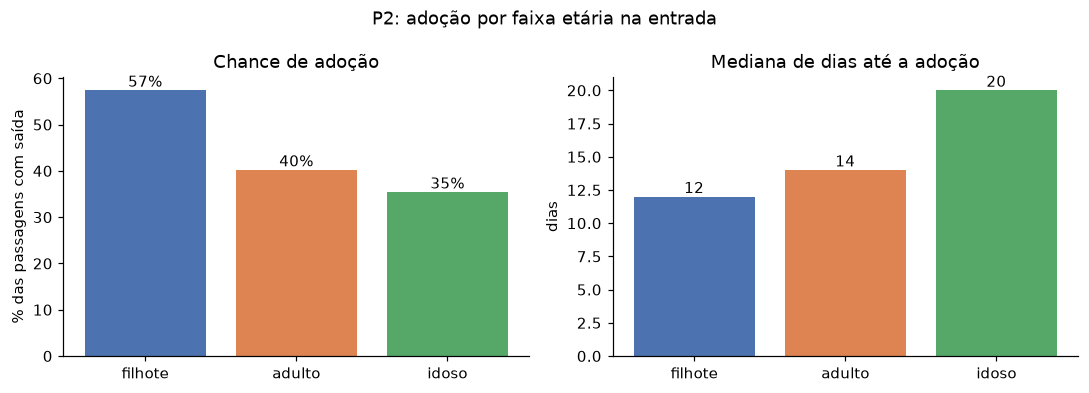

desfecho,adocao,transferencia,devolvido_ao_dono,eutanasia
faixa_etaria,,,,
filhote,57.4,37.3,1.0,2.3
adulto,40.2,42.4,9.6,5.5
idoso,35.4,27.4,17.4,16.1


In [6]:
p2 = indicadores(com_saida, "faixa_etaria").reindex(FAIXAS)
print(p2)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
cores = [CORES[f] for f in FAIXAS]
ax[0].bar(FAIXAS, p2["chance_adocao"], color=cores)
ax[0].set_title("Chance de adoção")
ax[0].set_ylabel("% das passagens com saída")
ax[1].bar(FAIXAS, p2["mediana_dias"], color=cores)
ax[1].set_title("Mediana de dias até a adoção")
ax[1].set_ylabel("dias")
for eixo, coluna, fmt in [(ax[0], "chance_adocao", "{:.0f}%"), (ax[1], "mediana_dias", "{:.0f}")]:
    for x, v in enumerate(p2[coluna]):
        eixo.text(x, v, fmt.format(v), ha="center", va="bottom")
fig.suptitle("P2: adoção por faixa etária na entrada")
plt.tight_layout()
plt.show()

# para onde vão os que não são adotados
(100 * pd.crosstab(com_saida["faixa_etaria"], com_saida["desfecho"], normalize="index")).reindex(FAIXAS)[
    ["adocao", "transferencia", "devolvido_ao_dono", "eutanasia"]].round(1)

**Interpretação:** sim, a idade pesa nas duas medidas. A chance de adoção cai de **57% nos filhotes para 40% nos adultos e 35% nos idosos**, e a mediana de espera sobe de 12 para 14 e 20 dias. A tabela de destinos mostra para onde vão os mais velhos que não são adotados: 17% dos idosos voltam para o dono e 16% são eutanasiados, contra 1% e 2% dos filhotes. Ou seja, parte da "chance menor" dos idosos é porque muitos tinham dono (e não estavam disponíveis para adoção) ou chegaram em estado grave.

### 3.2 P1 – Gatos pretos esperam mais e são adotados menos?

                           passagens  chance_adocao  adocoes_diretas  mediana_dias
faixa_etaria cor                                                                  
filhote      outras cores      39289           57.9            15134          11.0
             preto              6237           54.3             2294          17.0
adulto       outras cores      18796           40.7             6614          14.0
             preto              2582           37.0              824          18.0
idoso        outras cores       1773           35.9              490          19.0
             preto               221           30.8               52          30.5


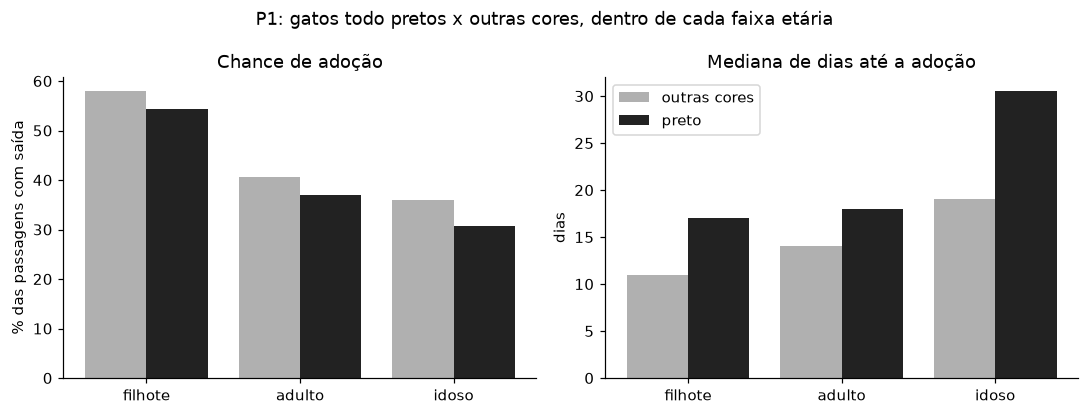

In [7]:
com_saida["cor"] = com_saida["is_black"].map({True: "preto", False: "outras cores"})
p1 = indicadores(com_saida, ["faixa_etaria", "cor"]).reindex(FAIXAS, level=0)
print(p1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.arange(len(FAIXAS))
for desloc, cor, cor_barra in [(-0.2, "outras cores", "#B0B0B0"), (0.2, "preto", "#222222")]:
    dados = p1.xs(cor, level="cor").reindex(FAIXAS)
    ax[0].bar(x + desloc, dados["chance_adocao"], width=0.4, color=cor_barra, label=cor)
    ax[1].bar(x + desloc, dados["mediana_dias"], width=0.4, color=cor_barra, label=cor)
for eixo, titulo, rotulo in [(ax[0], "Chance de adoção", "% das passagens com saída"),
                             (ax[1], "Mediana de dias até a adoção", "dias")]:
    eixo.set_xticks(x, FAIXAS)
    eixo.set_title(titulo)
    eixo.set_ylabel(rotulo)
ax[1].legend()
fig.suptitle("P1: gatos todo pretos x outras cores, dentro de cada faixa etária")
plt.tight_layout()
plt.show()

**Interpretação:** em **todas as faixas etárias** o gato todo preto tem chance de adoção menor (3,6 a 5,1 pontos percentuais a menos) e espera mais (filhotes: 17 dias contra 11; adultos: 18 contra 14). Como a comparação é feita dentro de cada faixa, a diferença não é efeito da idade. Os dados **apoiam a crença** da pergunta 1, mas o efeito é moderado: muito menor que o da idade, do nome ou da condição de entrada (próxima seção). Nos idosos a diferença parece maior (30,5 contra 19 dias), mas são só 52 adoções de idosos pretos, então esse número é pouco confiável.

### 3.3 P3 a P6 – Nome, castração, condição e tipo de entrada

Para comparar várias características num gráfico só, mostramos a **diferença** em relação a um grupo de referência: quantos pontos percentuais a chance de adoção sobe ou desce, e quantos dias a mais ou a menos o gato espera. Ficam só filhotes e adultos, porque os idosos são poucos em vários grupos (ver tabela).

                      comparação   faixa  n grupo  n referência  chance grupo  chance referência  diferença chance (p.p.)  diferença mediana (dias)
         P3: sem nome x com nome filhote    21869         23657          31.0               81.8                    -50.8                     -12.0
         P3: sem nome x com nome  adulto     7567         13811           7.4               58.2                    -50.8                     -10.0
         P3: sem nome x com nome   idoso      346          1648           0.9               42.6                    -41.7                     -14.5
     P4: castrado x não castrado filhote     1903         40089          68.4               61.9                      6.5                      -9.0
     P4: castrado x não castrado  adulto     9215         10710          48.5               38.6                      9.9                      -3.0
     P4: castrado x não castrado   idoso     1709           261          40.1                7.7                

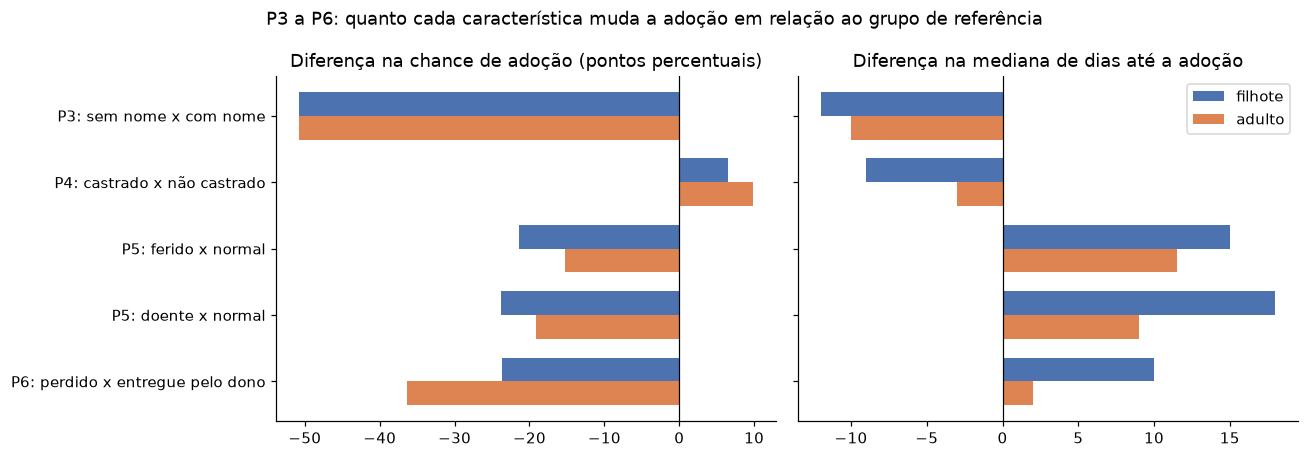

In [8]:
# cada comparação: (pergunta, coluna, grupo comparado, grupo de referência)
comparacoes = [
    ("P3: sem nome x com nome", "tem_nome", False, True),
    ("P4: castrado x não castrado", "castrado", True, False),
    ("P5: ferido x normal", "condicao_entrada", "ferido", "normal"),
    ("P5: doente x normal", "condicao_entrada", "doente", "normal"),
    ("P6: perdido x entregue pelo dono", "tipo_entrada", "perdido", "entregue_pelo_dono"),
]

linhas = []
for rotulo, coluna, grupo, referencia in comparacoes:
    t = indicadores(com_saida, ["faixa_etaria", coluna])
    for faixa in FAIXAS:
        g, r = t.loc[(faixa, grupo)], t.loc[(faixa, referencia)]
        linhas.append({
            "comparação": rotulo, "faixa": faixa,
            "n grupo": int(g["passagens"]), "n referência": int(r["passagens"]),
            "chance grupo": g["chance_adocao"], "chance referência": r["chance_adocao"],
            "diferença chance (p.p.)": round(g["chance_adocao"] - r["chance_adocao"], 1),
            "diferença mediana (dias)": g["mediana_dias"] - r["mediana_dias"],
        })
diferencas = pd.DataFrame(linhas)
print(diferencas.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
rotulos = [c[0] for c in comparacoes]
y = np.arange(len(rotulos))
for desloc, faixa in [(-0.18, "filhote"), (0.18, "adulto")]:
    d = diferencas[diferencas["faixa"] == faixa].set_index("comparação").loc[rotulos]
    ax[0].barh(y + desloc, d["diferença chance (p.p.)"], height=0.36, color=CORES[faixa], label=faixa)
    ax[1].barh(y + desloc, d["diferença mediana (dias)"], height=0.36, color=CORES[faixa], label=faixa)
for eixo, titulo in [(ax[0], "Diferença na chance de adoção (pontos percentuais)"),
                     (ax[1], "Diferença na mediana de dias até a adoção")]:
    eixo.axvline(0, color="black", linewidth=0.8)
    eixo.set_title(titulo)
ax[0].set_yticks(y, rotulos)
ax[0].invert_yaxis()
ax[1].legend()
fig.suptitle("P3 a P6: quanto cada característica muda a adoção em relação ao grupo de referência")
plt.tight_layout()
plt.show()

**Interpretação:**
- **P3 (nome):** é a maior diferença: sem nome, a chance de adoção cai **51 pontos** (filhotes: 31% contra 82%). Mas os poucos sem nome que são adotados saem *mais rápido*. Isso sugere que o nome é mais **consequência do processo do abrigo** do que uma característica do gato: o abrigo dá nome a quem vai para adoção (os nomes com `*`, que se dizem dados pelo abrigo, têm 64% a 79% de chance de adoção), e quem segue sem nome geralmente é transferido logo. É uma associação forte, mas não dá para dizer que "dar um nome" causa adoção.
- **P4 (castração):** chegar castrado aumenta a chance (+6,5 pontos nos filhotes, +9,9 nos adultos) e encurta a espera. Gato que chega castrado geralmente já tinha um dono, o que pode explicar parte do efeito.
- **P5 (saúde):** feridos e doentes têm chance **15 a 24 pontos menor** e esperam **9 a 18 dias a mais**. Nos filhotes o efeito no tempo é maior, provavelmente porque precisam se recuperar antes de ficarem disponíveis.
- **P6 (tipo de entrada):** gatos perdidos são bem menos adotados que os entregues pelo dono (−24 pontos nos filhotes, −36 nos adultos). Mas isso não é rejeição: os perdidos são os que podem voltar para o dono ou ser transferidos para parceiros.

Em todas as comparações, o sentido da diferença é o mesmo para filhotes e adultos, o que dá mais segurança ao resultado. São **associações, não causas**.

### 3.4 P7 – O mês de entrada muda o tempo até a adoção?

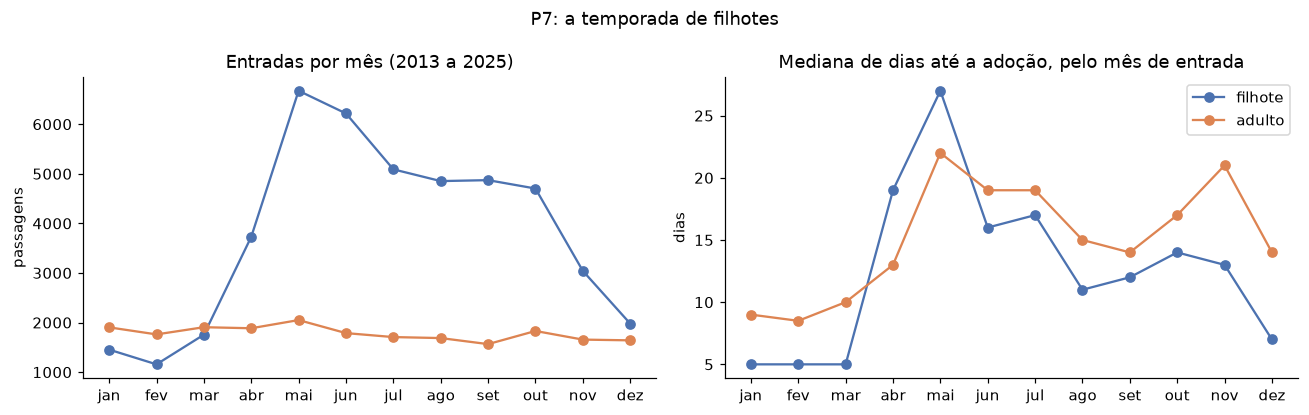

,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
faixa_etaria,,,,,,,,,,,,
filhote,5.0,5.0,5.0,19.0,27.0,16.0,17.0,11.0,12.0,14.0,13.0,7.0
adulto,9.0,8.5,10.0,13.0,22.0,19.0,19.0,15.0,14.0,17.0,21.0,14.0
idoso,13.0,18.0,18.0,32.0,30.5,29.0,16.0,15.5,19.0,13.0,29.5,18.0


In [9]:
com_saida["mes_entrada"] = com_saida["data_entrada"].dt.month
p7 = indicadores(com_saida, ["faixa_etaria", "mes_entrada"])
meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for faixa in ["filhote", "adulto"]:
    d = p7.loc[faixa]
    ax[0].plot(meses, d["passagens"], marker="o", color=CORES[faixa], label=faixa)
    ax[1].plot(meses, d["mediana_dias"], marker="o", color=CORES[faixa], label=faixa)
ax[0].set_title("Entradas por mês (2013 a 2025)")
ax[0].set_ylabel("passagens")
ax[1].set_title("Mediana de dias até a adoção, pelo mês de entrada")
ax[1].set_ylabel("dias")
ax[1].legend()
fig.suptitle("P7: a temporada de filhotes")
plt.tight_layout()
plt.show()

p7["mediana_dias"].unstack().reindex(FAIXAS).set_axis(meses, axis=1)

**Interpretação:** existe uma **temporada de filhotes**. As entradas de filhotes sobem de ~1.200 em fevereiro para **~6.700 em maio**, enquanto as de adultos ficam estáveis o ano todo. Junto com a lotação, o tempo de espera dispara: filhotes que entram de janeiro a março são adotados em **5 dias** (mediana), e os que entram em maio levam **27 dias**, mais de cinco vezes mais. Os adultos também esperam mais em maio (22 dias contra 8 a 10 no começo do ano), porque passam a disputar adotantes com centenas de filhotes. Para o abrigo, isso indica que a primavera e o início do verão (abril a julho, no hemisfério norte) são o período que mais precisa de campanhas de adoção e de lares temporários.

## 4. Amostragem e representatividade

**Não usamos amostragem:** todas as análises usam a base inteira do abrigo, 69.309 passagens de gatos de out/2013 a mai/2025. A pergunta, então, não é se a amostra foi bem sorteada, mas **o que essa base representa** e o que pode distorcer os resultados. A tabela abaixo mostra como o volume e a chance de adoção mudaram ao longo dos anos.

In [10]:
por_ano = gatos.groupby(gatos["data_entrada"].dt.year).agg(
    passagens=("animal_id", "size"),
    sem_saida=("desfecho", lambda d: (d == "sem_saida").sum()),
)
por_ano["chance_adocao"] = (100 * com_saida.groupby(com_saida["data_entrada"].dt.year)["adotado"].mean()).round(1)
por_ano["pct_foster"] = (100 * adocoes.groupby(adocoes["data_entrada"].dt.year)["foster"].mean()).round(1)
por_ano.T

data_entrada,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
passagens,1309.0,6937.0,7484.0,6632.0,6488.0,6018.0,7880.0,3448.0,5112.0,4684.0,5600.0,6046.0,1671.0
sem_saida,0.0,8.0,3.0,3.0,4.0,0.0,2.0,0.0,0.0,0.0,4.0,14.0,372.0
chance_adocao,41.9,36.7,40.0,47.0,49.4,50.0,47.4,55.7,62.7,66.2,62.7,63.7,55.0
pct_foster,17.1,25.6,28.7,29.4,23.7,26.6,24.2,55.4,29.4,25.8,30.7,27.6,14.0


**Origem e abrangência:** os registros são de um único abrigo municipal, o Austin Animal Center (Texas, EUA), publicados pela própria prefeitura. A base cobre quase 12 anos e todos os gatos que passaram pelo abrigo, e não uma seleção deles.

**Representam o problema?** Para a pergunta "o que se associa à adoção **neste abrigo**", sim: é a população inteira, com milhares de casos em quase todos os grupos comparados. Mas os resultados **não valem automaticamente para outros abrigos**: Austin segue uma política *no-kill* (eutanasia rara), tem uma rede grande de parceiros que recebem transferências e fica no hemisfério norte (a temporada de filhotes de abril a julho seria outra no Brasil).

**Limitações e vieses que podem influenciar os resultados:**
- **Mudança ao longo do tempo:** a chance de adoção subiu de 37% (2014) para 66% (2022), enquanto as transferências caíram de 51% para 26%. As práticas do abrigo mudaram, então um resultado médio de 12 anos mistura períodos diferentes. Isso afeta diretamente o ML (seção 5).
- **2020 (COVID):** metade das entradas de um ano normal, e 55% das adoções passaram por lar temporário (Foster), contra ~27% nos outros anos.
- **Dados censurados em 2025:** 372 passagens de 2025 não têm saída (gatos ainda no abrigo quando a base congelou). Por isso o tempo de espera de 2025 parece menor do que foi.
- **Adoções Foster:** o tempo delas inclui dias em lar temporário. Por isso foram separadas nas análises de tempo.
- **Perfil de entrada:** 77% dos gatos chegam perdidos. Os grupos menores (idosos, pedidos de eutanasia, condições raras) têm poucos casos e foram interpretados com cuidado.
- **Significado das colunas:** o portal não tem dicionário de dados. O sentido de `*` no nome, `Disposal` e `Foster` foi deduzido por nós (RA1).
- **Associação, não causa:** os dados são observacionais. Por exemplo, gatos castrados chegam castrados porque tinham dono, e não dá para separar os dois efeitos.

## 5. Aplicação de Machine Learning

### 5.1 Definição do problema preditivo

**Problema:** quando um gato chega ao abrigo, dá para prever se ele **vai ser adotado**? Um modelo assim ajudaria o abrigo a identificar logo na entrada os gatos com menor chance, para dar mais visibilidade a eles.

- **Tipo:** **classificação** binária. Regressão dos dias no abrigo foi descartada porque o tempo é muito assimétrico (seção 2) e depende do desfecho.
- **Target:** `adotado` = 1 se o desfecho é `adocao`, 0 caso contrário (transferência, devolução ao dono, eutanasia...). Só passagens com saída.
- **Features:** só o que o abrigo sabe **na chegada**: idade, mês de entrada, sexo, castração, cor (`is_black` e `cor_principal`), raça, tipo e condição de entrada. Ficam de fora `dias_no_abrigo`, `data_saida` e `subtipo_desfecho`, que só existem depois da saída e entregariam a resposta (**vazamento de dados**).
- **Nome:** `tem_nome` e `nome_com_asterisco` são testados à parte. A seção 3.3 mostrou que o nome parece ser dado pelo abrigo a quem vai para adoção, então ele pode carregar parte da resposta.

**Separação treino/teste temporal:** treinamos com os gatos que entraram até 2022 e testamos com os que entraram em 2023 e 2024. Assim o teste simula o uso real (prever gatos novos com o que se aprendeu do passado), o que é mais exigente que um sorteio aleatório. 2025 fica de fora porque as passagens ainda sem saída deixariam no teste só os gatos que saíram rápido.

O preparo e os modelos ficam em `src/modelo.py`, usado também pelo dashboard.

In [11]:
import sys

from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score)

sys.path.append("../src")
import modelo

base = modelo.preparar_base_ml(gatos)
treino, teste = modelo.separar_treino_teste(base)
print(f"Treino: {len(treino)} passagens (2013 a 2022) | adotados: {treino['adotado'].mean():.1%}")
print(f"Teste:  {len(teste)} passagens (2023 e 2024) | adotados: {teste['adotado'].mean():.1%}")
treino[modelo.features(usa_nome=False)].head(3)

Treino: 55971 passagens (2013 a 2022) | adotados: 48.9%
Teste:  11628 passagens (2023 e 2024) | adotados: 63.2%


,idade_entrada_meses,mes_entrada,sexo,castrado,is_black,cor_principal,raca,tipo_entrada,condicao_entrada
0,0.2,10,desconhecido,desconhecido,False,Orange,Domestic Shorthair,perdido,normal
1,0.2,10,desconhecido,desconhecido,False,Orange,Domestic Shorthair,perdido,normal
2,0.2,10,desconhecido,desconhecido,False,Orange,Domestic Shorthair,perdido,normal


### 5.2 Treinamento, previsões e métricas

Treinamos três modelos, cada um em duas versões (sem e com o nome):
- **baseline:** sempre prevê a classe mais comum no treino. Serve de régua: um modelo útil precisa ser melhor que ele;
- **regressão logística:** modelo linear, simples e interpretável;
- **random forest:** conjunto de árvores de decisão, que capta combinações entre as features (por exemplo, filhote **e** maio).

Métricas, todas calculadas no teste:
- **acurácia:** % de acertos;
- **precisão:** dos que o modelo disse "adotado", quantos foram;
- **recall:** dos adotados de verdade, quantos o modelo encontrou;
- **F1:** equilíbrio entre precisão e recall;
- **AUC:** capacidade de ordenar os gatos do mais para o menos provável de ser adotado (0,5 = sorteio, 1 = perfeito). Não depende do corte de 50%, por isso é a principal para comparar os modelos.

In [12]:
modelos = {
    "baseline": lambda usa_nome: DummyClassifier(strategy="most_frequent"),
    "regressão logística": lambda usa_nome: modelo.criar_modelo("regressao_logistica", usa_nome),
    "random forest": lambda usa_nome: modelo.criar_modelo("random_forest", usa_nome),
}

resultados, treinados = [], {}
for usa_nome in [False, True]:
    colunas = modelo.features(usa_nome)
    for nome, criar in modelos.items():
        m = criar(usa_nome).fit(treino[colunas], treino["adotado"])
        previsto = m.predict(teste[colunas])
        prob = m.predict_proba(teste[colunas])[:, 1]
        treinados[(nome, usa_nome)] = m
        resultados.append({
            "versão": "com nome" if usa_nome else "sem nome", "modelo": nome,
            "acurácia": accuracy_score(teste["adotado"], previsto),
            "precisão": precision_score(teste["adotado"], previsto, zero_division=0),
            "recall": recall_score(teste["adotado"], previsto),
            "F1": f1_score(teste["adotado"], previsto),
            "AUC": roc_auc_score(teste["adotado"], prob),
        })

pd.DataFrame(resultados).set_index(["versão", "modelo"]).round(3)

acurácia  precisão  recall     F1    AUC
versão   modelo                                                       
sem nome baseline                0.368     0.000   0.000  0.000  0.500
         regressão logística     0.716     0.776   0.775  0.775  0.747
         random forest           0.708     0.860   0.642  0.735  0.796
com nome baseline                0.368     0.000   0.000  0.000  0.500
         regressão logística     0.766     0.871   0.738  0.799  0.854
         random forest           0.791     0.879   0.775  0.824  0.887

**Interpretação:**
- O **baseline** prevê sempre "não adotado", que era a classe mais comum no treino (51%). No teste ele acerta só 37%, porque em 2023 e 2024 a adoção virou maioria (63%). É a mudança ao longo do tempo da seção 4 aparecendo na prática: o padrão do passado não vale igual para o futuro.
- **Sem nome**, os dois modelos são bem melhores que o baseline: acertam ~71% e têm **AUC de 0,75 (logística) e 0,80 (random forest)**. A random forest ordena melhor os gatos porque capta combinações (por exemplo, a idade pesa diferente conforme a condição de entrada).
- **Com nome**, o AUC sobe para 0,89. Esse salto confirma a suspeita da seção 3.3: o nome carrega parte da resposta, porque o abrigo nomeia quem vai para adoção. Um modelo usado na chegada do gato não poderia contar com essa informação, então **essa versão superestima o desempenho real**.

### 5.3 O modelo escolhido: random forest sem nome

Escolhemos a **random forest sem o nome**: é o melhor modelo que usa só características do gato na chegada (sem a variável suspeita de vazamento). Abaixo, a matriz de confusão no teste e a **importância de cada feature** (quanto o AUC piora quando embaralhamos aquela coluna).

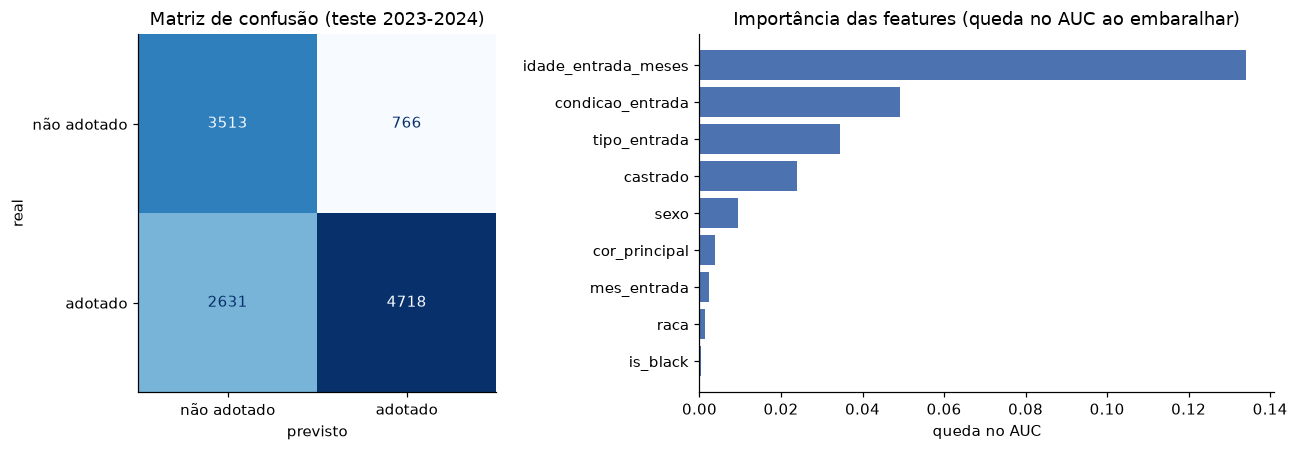

,idade_entrada_meses,sexo,castrado,is_black,tipo_entrada,condicao_entrada,mes_entrada,prob_adocao,adotado
64908,0.2,macho,nao,False,perdido,neonatal,7,0.25,0
66021,24.0,femea,nao,False,entregue_pelo_dono,normal,9,0.62,1
63319,24.0,femea,nao,False,perdido,normal,5,0.33,0
63978,1.0,macho,nao,False,perdido,normal,5,0.71,1
56580,36.0,macho,nao,False,entregue_pelo_dono,normal,3,0.63,1
56849,12.0,macho,nao,False,perdido,normal,3,0.29,1


In [13]:
escolhido = treinados[("random forest", False)]
colunas = modelo.features(usa_nome=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
ConfusionMatrixDisplay.from_estimator(escolhido, teste[colunas], teste["adotado"],
                                      display_labels=["não adotado", "adotado"], cmap="Blues", ax=ax[0],
                                      colorbar=False)
ax[0].set_title("Matriz de confusão (teste 2023-2024)")
ax[0].set_xlabel("previsto")
ax[0].set_ylabel("real")

imp = permutation_importance(escolhido, teste[colunas], teste["adotado"], scoring="roc_auc",
                             n_repeats=5, random_state=42)
importancia = pd.Series(imp.importances_mean, index=colunas).sort_values()
ax[1].barh(importancia.index, importancia.values, color="#4C72B0")
ax[1].set_title("Importância das features (queda no AUC ao embaralhar)")
ax[1].set_xlabel("queda no AUC")
plt.tight_layout()
plt.show()

# exemplos de previsões: probabilidade de adoção que o modelo dá para alguns gatos do teste
exemplos = teste.sample(6, random_state=7)
exemplos.assign(prob_adocao=escolhido.predict_proba(exemplos[colunas])[:, 1].round(2))[
    ["idade_entrada_meses", "sexo", "castrado", "is_black", "tipo_entrada", "condicao_entrada", "mes_entrada",
     "prob_adocao", "adotado"]]

**Interpretação:**
- A **idade** é de longe a feature mais importante, seguida da **condição de entrada**, do **tipo de entrada** e da **castração**. É a mesma ordem de efeitos vista nos gráficos da seção 3.
- `is_black` quase não muda o AUC. Isso não contradiz a P1: o efeito da cor existe, mas é pequeno perto da idade e da saúde, e parte dele já está em `cor_principal`.
- A matriz de confusão mostra o ponto fraco: o modelo acerta 82% dos não adotados, mas **deixa passar 2.631 adotados** (recall de 64%). Ele aprendeu com um período em que se adotava menos e por isso é pessimista com os gatos de 2023 e 2024. Na prática, o corte de 50% poderia ser ajustado, ou o modelo retreinado com dados recentes.
- Nos exemplos, o modelo dá probabilidade alta para filhotes saudáveis e para gatos entregues pelo dono, e baixa para neonatos e adultos perdidos, o que é coerente com a análise.

## 6. Conclusões

**Principais resultados:** metade das passagens de gatos termina em adoção (51%), e metade dos adotados sai em até **13 dias**. O tempo é muito assimétrico (média de 25 dias), o que justificou o uso da mediana. Comparando dentro de cada faixa etária, as características na chegada associadas a **menor chance e maior espera** são:
1. **idade** (filhotes 57% de chance, idosos 35%);
2. **saúde** (ferido ou doente: −15 a −24 pontos);
3. **tipo de entrada** (perdidos são menos adotados, mas porque muitos voltam ao dono ou são transferidos);
4. **não ser castrado**;
5. ser **todo preto** (−4 a −5 pontos e de 4 a 6 dias a mais).

A **temporada de filhotes** (abril a julho) multiplica a espera por cinco. Ter nome tem a maior associação de todas, mas parece ser consequência do processo do abrigo, não uma característica do gato.

**Desempenho do modelo:** a random forest, usando só o que se sabe na chegada, ordena bem os gatos pela chance de adoção (**AUC 0,80**, contra 0,50 do sorteio) e acerta 71% no teste de 2023 e 2024. Ela é útil para apontar gatos com pouca chance logo na entrada, mas subestima as adoções recentes porque aprendeu com anos em que se adotava menos.

**Limitações:** é um único abrigo, com política e período específicos; as práticas mudaram ao longo dos anos (a adoção subiu de 37% para 66%); há dados censurados em 2025 e adoções Foster com tempo de lar temporário; os resultados são associações, não causas; e o significado de algumas colunas foi deduzido por nós.

**Relação com o problema:** os dados respondem às perguntas do RA1. A crença sobre os **gatos pretos se confirma**, mas com efeito moderado. **Idade, saúde e época de chegada** pesam muito mais. Para o abrigo, isso sugere concentrar as campanhas nos **adultos e idosos**, nos **gatos que chegam feridos ou doentes** e no período de **abril a julho**, e usar o modelo para sinalizar logo na entrada os gatos que mais precisam de visibilidade. O dashboard (`dashboard/app.py`) junta esses indicadores e o modelo numa interface para o abrigo consultar.